# Predicting RankMe and variance on a slowly refreshed bank

**Complete** · Finished both banks · ETA 0h 00m 00s

seed 2026 at 80,000, seed 2027 at 80,000, seed 2028 at 80,000. Scored all predictors through **80,000** arrivals. Updated 2026-11-11T11:56:02+01:00.

## RMSE over the stream

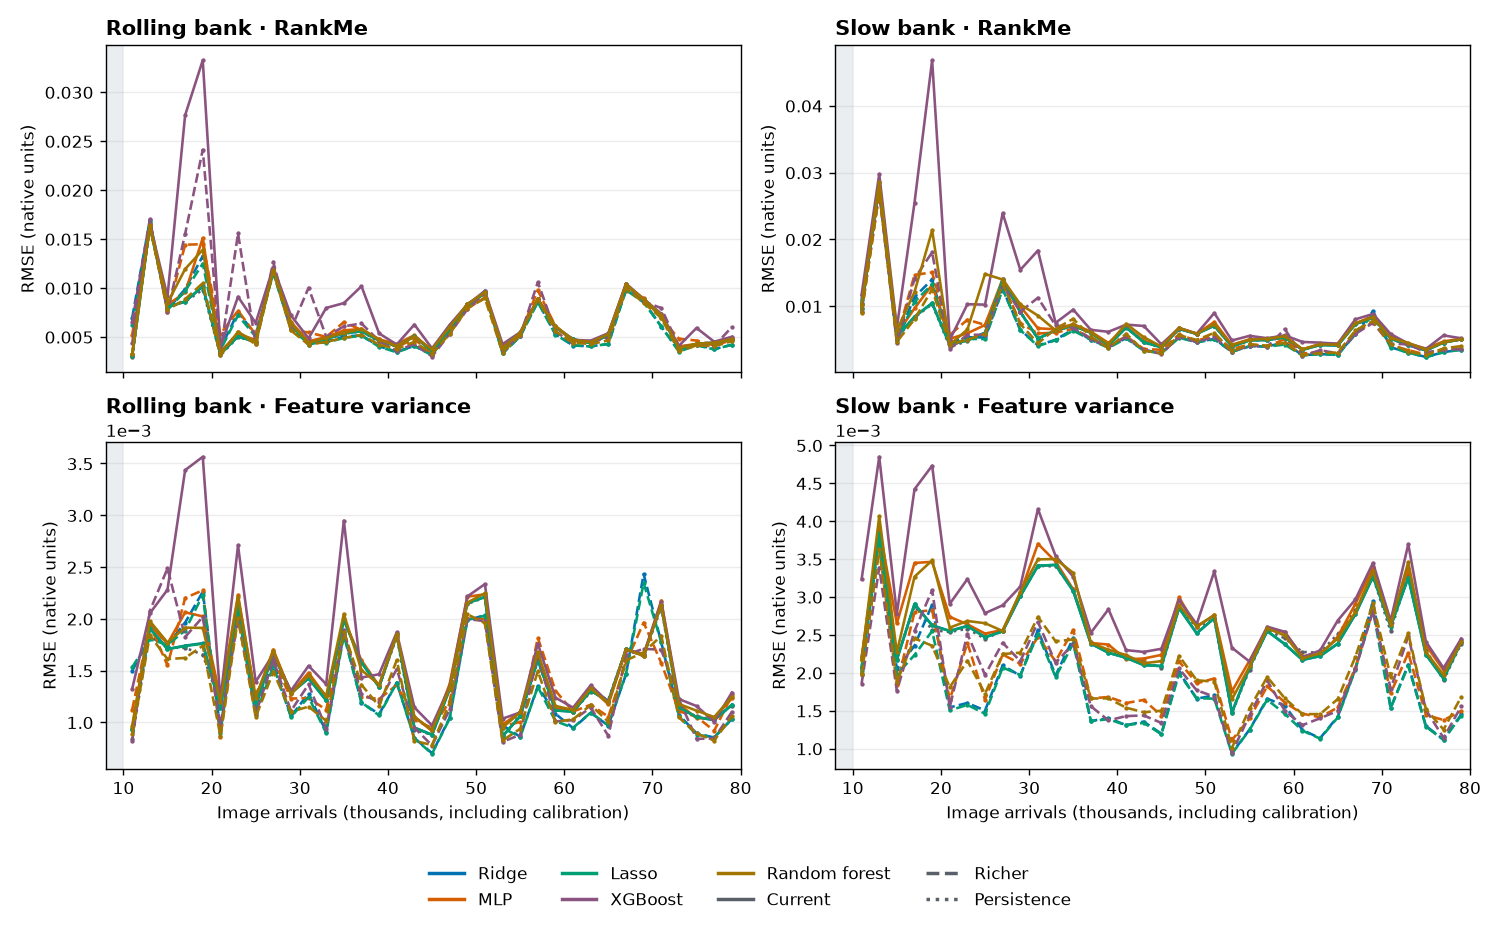

## Pooled held-out RMSE

| Bank | Predictor | Features | RankMe | Variance | RankMe gain vs persistence | Variance gain vs persistence |
| --- | --- | --- | --- | --- | --- | --- |
 | Rolling bank | Ridge | Current | 0.00688158 | 0.00149667 | -0.4% | -0.6% | 
 | Rolling bank | Persistence | — | 0.00685355 | 0.00148834 | +0.0% | +0.0% | 
 | Rolling bank | Ridge | Richer | 0.00704422 | 0.00142699 | -2.8% | +4.1% | 
 | Rolling bank | MLP | Current | 0.00725781 | 0.0015469 | -5.9% | -3.9% | 
 | Rolling bank | MLP | Richer | 0.00753204 | 0.00146435 | -9.9% | +1.6% | 
 | Rolling bank | Lasso | Current | 0.00687853 | 0.00149594 | -0.4% | -0.5% | 
 | Rolling bank | Lasso | Richer | 0.0069115 | 0.00140907 | -0.8% | +5.3% | 
 | Rolling bank | XGBoost | Current | 0.0103125 | 0.00179874 | -50.5% | -20.9% | 
 | Rolling bank | XGBoost | Richer | 0.00877547 | 0.00143229 | -28.0% | +3.8% | 
 | Rolling bank | Random forest | Current | 0.0072802 | 0.00153647 | -6.2% | -3.2% | 
 | Rolling bank | Random forest | Richer | 0.0066922 | 0.00135967 | +2.4% | +8.6% | 
 | Slow bank | Ridge | Current | 0.00790902 | 0.00260481 | -0.6% | +0.2% | 
 | Slow bank | Persistence | — | 0.00786233 | 0.00261077 | +0.0% | +0.0% | 
 | Slow bank | Ridge | Richer | 0.00769063 | 0.00188881 | +2.2% | +27.7% | 
 | Slow bank | MLP | Current | 0.00830253 | 0.00274201 | -5.6% | -5.0% | 
 | Slow bank | MLP | Richer | 0.00795298 | 0.00200869 | -1.2% | +23.1% | 
 | Slow bank | Lasso | Current | 0.00790474 | 0.00260418 | -0.5% | +0.3% | 
 | Slow bank | Lasso | Richer | 0.00744374 | 0.00183957 | +5.3% | +29.5% | 
 | Slow bank | XGBoost | Current | 0.0133483 | 0.00304385 | -69.8% | -16.6% | 
 | Slow bank | XGBoost | Richer | 0.00821337 | 0.00197781 | -4.5% | +24.2% | 
 | Slow bank | Random forest | Current | 0.00921679 | 0.00271487 | -17.2% | -4.0% | 
 | Slow bank | Random forest | Richer | 0.00745397 | 0.00202805 | +5.2% | +22.3% | 

## Protocol

Both banks start with the last 128 calibration images at arrival 8,000. The rolling bank replaces the oldest image after every arrival. The slow bank replaces the oldest image with the current frame after every 16th arrival. RankMe and mean feature variance measure the same bank members before and after the update. Loss inputs and the recorded balanced MAE actions are shared across both banks.

Both variants use arrivals 8,001–10,000 for predictor warm-up. After fitting at 10,000, all five families refit at 4,000-arrival boundaries using up to 16,000 past arrivals and the same hyperparameters and label-free feature sets. Each point pools errors on non-skip updates across the seeds in one 2,000-arrival window. Persistence predicts zero change. Relative gains use each bank’s own persistence RMSE so changes in target scale are visible.

In [ ]:
# Run this cell to refresh the open notebook during the background run.
from IPython.display import clear_output, display, Image, Markdown
from pathlib import Path
import json, time

folder = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\slow-health-benchmark')
while True:
    try:
        status = json.loads((folder / 'status.json').read_text(encoding='utf-8'))
        plot = (folder / 'rmse.png').read_bytes()
    except (PermissionError, FileNotFoundError):
        time.sleep(2)
        continue
    eta = status['eta_seconds']
    eta_text = f'{eta / 60:.1f} min' if eta is not None else 'estimating'
    clear_output(wait=True)
    display(Markdown(f"**{status['state']}** · {status['stage']} · ETA {eta_text} · "
                     f"scored through {status['compared_through']:,} arrivals · {status['cursors']}"))
    display(Image(data=plot))
    if status['state'] in ('complete', 'stopped', 'failed'):
        if status.get('error'):
            display(Markdown(status['error']))
        break
    time.sleep(10)
